In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [112]:
df= pd.read_csv("knn_student_result_large_dataset.csv")
df.head()

,Age,Study_Hours,Attendance,Result
0,24,3.0,53.8,Fail
1,21,1.9,60.6,Fail
2,30,5.7,60.5,Pass
3,28,8.6,75.3,Pass
4,25,1.6,40.0,Fail


# check dataset

In [113]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          500 non-null    int64  
 1   Study_Hours  500 non-null    float64
 2   Attendance   500 non-null    float64
 3   Result       500 non-null    str    
dtypes: float64(2), int64(1), str(1)
memory usage: 15.8 KB


In [114]:
df.describe()

,Age,Study_Hours,Attendance
count,500.000000,500.000000,500.000000
mean,23.900000,6.545600,73.145600
std,3.774984,3.118321,15.403438
min,18.000000,1.000000,40.000000
25%,21.000000,3.800000,61.250000
50%,24.000000,6.800000,74.100000
75%,27.000000,9.100000,85.500000
max,30.000000,12.000000,100.000000


In [115]:
df.shape

(500, 4)

In [116]:
df.isnull().sum()

Age            0
Study_Hours    0
Attendance     0
Result         0
dtype: int64

In [117]:
df.columns

Index(['Age', 'Study_Hours', 'Attendance', 'Result'], dtype='str')

# Check pass/fail distribution

In [118]:
df['Result'].value_counts()

Result
Pass    292
Fail    208
Name: count, dtype: int64

<Axes: xlabel='Result'>

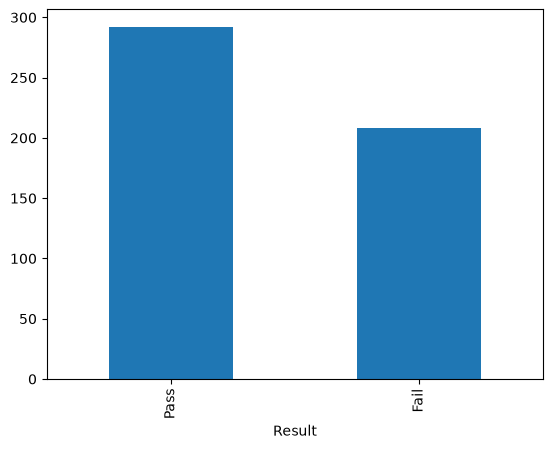

In [119]:
df['Result'].value_counts().plot(kind='bar')

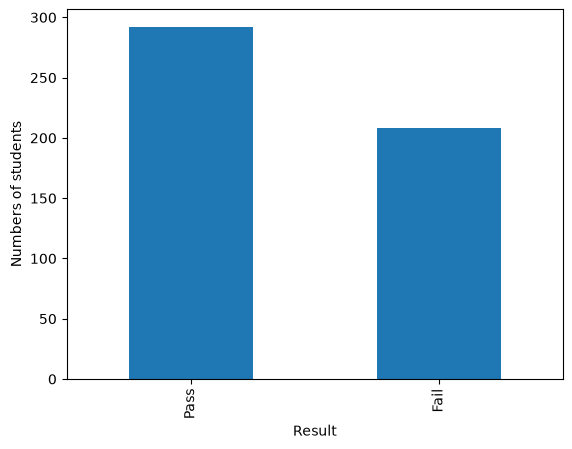

In [120]:
df['Result'].value_counts().plot(kind='bar')
plt.xlabel("Result")
plt.ylabel("Numbers of students")
plt.show()

# Seperate X and Y

In [121]:
X = df[['Age','Study_Hours','Attendance']]
y =df['Result']

# Split into training and testing data

In [122]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [123]:
print("training data:",X_train.shape)
print("Testing data:",X_test.shape)

training data: (400, 3)
Testing data: (100, 3)


# Feature scaling

In [124]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

#fit()= learn
#transform()= apply
#fit_transform = learn +apply

# Import KNN

In [125]:
from sklearn.neighbors import KNeighborsClassifier
#create a knn classifier with 5 neighbour
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model

In [126]:
knn.fit(X_train_scaled,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Fail','Pass']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# Make Prediction

In [127]:
y_pred = knn.predict(X_test_scaled)
y_pred[:10]

array(['Fail', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Fail',
       'Pass', 'Pass'], dtype=object)

# Compare actual and predicted

In [128]:
comparsion = pd.DataFrame({
'Actual': y_test.values,
'Predict': y_pred
})
comparsion.head(20)

,Actual,Predict
0,Fail,Fail
1,Pass,Pass
2,Pass,Pass
3,Fail,Pass
4,Pass,Pass
5,Pass,Pass
6,Pass,Pass
7,Fail,Fail
8,Pass,Pass
9,Pass,Pass


# Calculate Accuracy

In [129]:
from sklearn.metrics import accuracy_score

accuracy= accuracy_score(y_test,y_pred)


print("Accuracy:",accuracy)
print("Accuracy percentage:" ,accuracy*100,"%")

Accuracy: 0.9
Accuracy percentage: 90.0 %


# Confusion Matrix

In [130]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[40  7]
 [ 3 50]]


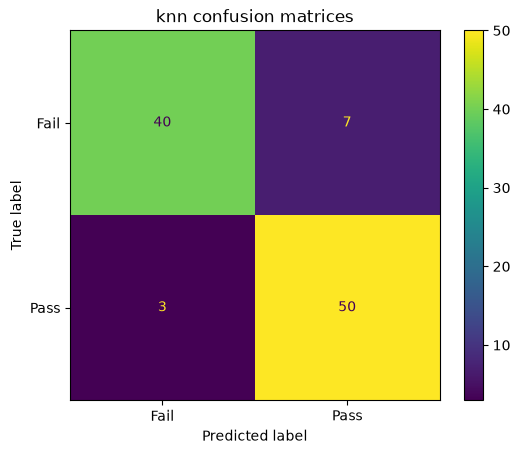

In [131]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

plt.title("knn confusion matrices")

plt.show()

# Classification Report

In [132]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

        Fail       0.93      0.85      0.89        47
        Pass       0.88      0.94      0.91        53

    accuracy                           0.90       100
   macro avg       0.90      0.90      0.90       100
weighted avg       0.90      0.90      0.90       100



# Test Different K Value

In [133]:
k_values = range(1,21)

accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled,y_train)

    y_pred=knn.predict(X_test_scaled)

    accuracy =accuracy_score(y_test,y_pred)

    accuracies.append(accuracy)

In [134]:
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("Best K:",best_k)
print("Best Accuracy:",best_accuracy)

Best K: 16
Best Accuracy: 0.92


# Visualize K vs Accuracy

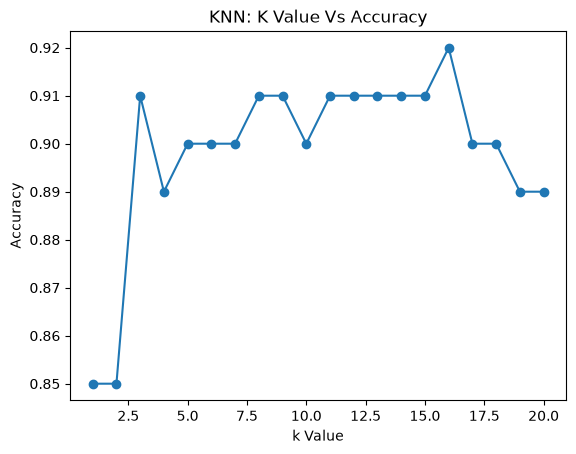

In [135]:
plt.plot(k_values,accuracies,marker="o")

plt.xlabel("k Value")
plt.ylabel("Accuracy")
plt.title("KNN: K Value Vs Accuracy")

plt.show()

# Train final model with best K

In [136]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)

best_knn.fit(X_train_scaled,y_train)



,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",16
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Fail','Pass']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [137]:
final_predictions = best_knn.predict(X_test_scaled)

final_accuracy = accuracy_score(y_test,final_predictions)

print("Final Accuracy:",final_accuracy)


Final Accuracy: 0.92


# Predict a completely new student

In [138]:
new_student = pd.DataFrame({
    "Age": [23],
    "Study_Hours":[8],
    "Attendance":[85]
})
new_student

,Age,Study_Hours,Attendance
0,23,8,85


In [139]:
# scale it
new_student_scaled = scaler.transform(new_student)

In [140]:
#predict
prediction = best_knn.predict(new_student_scaled)

print("Prediction Result:",prediction[0])


Prediction Result: Pass


# Model Deployment

In [144]:
#  Save the model and scaler for future use
import joblib

joblib.dump(best_knn,'knn_model.pkl')
joblib.dump(scaler,'scaler.pkl')

['scaler.pkl']

# Create a prediction function

In [145]:
def predict_result(age,study_hours,attendance):
    new_student=[[age,study_hours,attendance]]

    new_student_scaled = scaler.transform(new_student)

    prediction = best_knn.predict(new_student_scaled)
    return prediction[0]

In [147]:
result = predict_result(23,8,85)
print(result)

Pass


c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
